In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('data/raw.csv')
df.head()

,id,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,1,male,group A,master's degree,free/reduced,none,69,47,73
1,2,male,group D,some high school,free/reduced,completed,75,53,78
2,3,female,group A,master's degree,free/reduced,none,46,85,58
3,4,female,group E,associate's degree,standard,completed,98,78,61
4,5,male,group C,some high school,standard,completed,63,96,79


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2001 entries, 0 to 2000
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   id                           2001 non-null   int64
 1   gender                       2001 non-null   str  
 2   race_ethnicity               2001 non-null   str  
 3   parental_level_of_education  2001 non-null   str  
 4   lunch                        2001 non-null   str  
 5   test_preparation_course      2001 non-null   str  
 6   math_score                   2001 non-null   int64
 7   reading_score                2001 non-null   int64
 8   writing_score                2001 non-null   int64
dtypes: int64(4), str(5)
memory usage: 140.8 KB


In [4]:
df.describe()

,id,math_score,reading_score,writing_score
count,2001.000000,2001.000000,2001.000000,2001.000000
mean,1000.999500,67.519740,70.548726,70.060970
std,577.782399,19.299086,17.623613,17.777353
min,1.000000,35.000000,40.000000,40.000000
25%,501.000000,50.000000,55.000000,55.000000
50%,1001.000000,67.000000,71.000000,70.000000
75%,1501.000000,84.000000,86.000000,86.000000
max,2000.000000,100.000000,100.000000,100.000000


In [5]:
df.isna().sum()

id                             0
gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(1)

In [9]:
df.drop_duplicates(inplace=True)

In [10]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.nunique()

id                             2000
gender                            2
race_ethnicity                    5
parental_level_of_education       6
lunch                             2
test_preparation_course           2
math_score                       66
reading_score                    61
writing_score                    61
dtype: int64

In [16]:
print(df['gender'].unique)
print('*' * 50)

print(df['race_ethnicity'].unique)
print('*' * 50)


<bound method Series.unique of 0         male
1         male
2       female
3       female
4         male
         ...  
1995    female
1996    female
1997      male
1998    female
1999      male
Name: gender, Length: 2000, dtype: str>
**************************************************
<bound method Series.unique of 0       group A
1       group D
2       group A
3       group E
4       group C
         ...   
1995    group E
1996    group C
1997    group D
1998    group A
1999    group E
Name: race_ethnicity, Length: 2000, dtype: str>
**************************************************


In [19]:
print(df['parental_level_of_education'].unique)
print('*' * 50)

print(df['lunch'].unique)
print('*' * 50)

print(df['test_preparation_course'].unique)
print('*' * 50)

print(df['math_score'].unique)
print('*' * 50)

print(df['reading_score'].unique)
print('*' * 50)

print(df['writing_score'].unique)
print('*' * 50)



<bound method Series.unique of 0          master's degree
1         some high school
2          master's degree
3       associate's degree
4         some high school
               ...        
1995          some college
1996       master's degree
1997       master's degree
1998           high school
1999      some high school
Name: parental_level_of_education, Length: 2000, dtype: str>
**************************************************
<bound method Series.unique of 0       free/reduced
1       free/reduced
2       free/reduced
3           standard
4           standard
            ...     
1995    free/reduced
1996    free/reduced
1997    free/reduced
1998        standard
1999    free/reduced
Name: lunch, Length: 2000, dtype: str>
**************************************************
<bound method Series.unique of 0            none
1       completed
2            none
3       completed
4       completed
          ...    
1995    completed
1996         none
1997         none
1998         no

In [22]:
# define numerical & categorical columns correctly
numeric_features = [feature for feature in df.columns if df[feature].dtype != 'O' and df[feature].dtype != 'string']
categorical_features = [feature for feature in df.columns if df[feature].dtype == 'O' or df[feature].dtype == 'string']

# print columns
print('We have {} numerical features : {}'.format(len(numeric_features), numeric_features))
print('\nWe have {} categorical features : {}'.format(len(categorical_features), categorical_features))

We have 4 numerical features : ['id', 'math_score', 'reading_score', 'writing_score']

We have 5 categorical features : ['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course']


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 9 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   id                           2000 non-null   int64
 1   gender                       2000 non-null   str  
 2   race_ethnicity               2000 non-null   str  
 3   parental_level_of_education  2000 non-null   str  
 4   lunch                        2000 non-null   str  
 5   test_preparation_course      2000 non-null   str  
 6   math_score                   2000 non-null   int64
 7   reading_score                2000 non-null   int64
 8   writing_score                2000 non-null   int64
dtypes: int64(4), str(5)
memory usage: 140.8 KB


In [23]:
df['total score'] = df['math_score'] + df['reading_score'] + df['writing_score']
df['average'] = df['total score']/3
df.head()

,id,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total score,average
0,1,male,group A,master's degree,free/reduced,none,69,47,73,189,63.000000
1,2,male,group D,some high school,free/reduced,completed,75,53,78,206,68.666667
2,3,female,group A,master's degree,free/reduced,none,46,85,58,189,63.000000
3,4,female,group E,associate's degree,standard,completed,98,78,61,237,79.000000
4,5,male,group C,some high school,standard,completed,63,96,79,238,79.333333


In [24]:
reading_full = df[df['reading_score'] == 100]['average'].count()
writing_full = df[df['writing_score'] == 100]['average'].count()
math_full = df[df['math_score'] == 100]['average'].count()

print(f'Number of students with full marks in Maths: {math_full}')
print(f'Number of students with full marks in Writing: {writing_full}')
print(f'Number of students with full marks in Reading: {reading_full}')

Number of students with full marks in Maths: 37
Number of students with full marks in Writing: 35
Number of students with full marks in Reading: 36


In [25]:
reading_less_20 = df[df['reading_score'] <= 20]['average'].count()
writing_less_20 = df[df['writing_score'] <= 20]['average'].count()
math_less_20 = df[df['math_score'] <= 20]['average'].count()

print(f'Number of students with less than 20 marks in Maths: {math_less_20}')
print(f'Number of students with less than 20 marks in Writing: {writing_less_20}')
print(f'Number of students with less than 20 marks in Reading: {reading_less_20}')

Number of students with less than 20 marks in Maths: 0
Number of students with less than 20 marks in Writing: 0
Number of students with less than 20 marks in Reading: 0


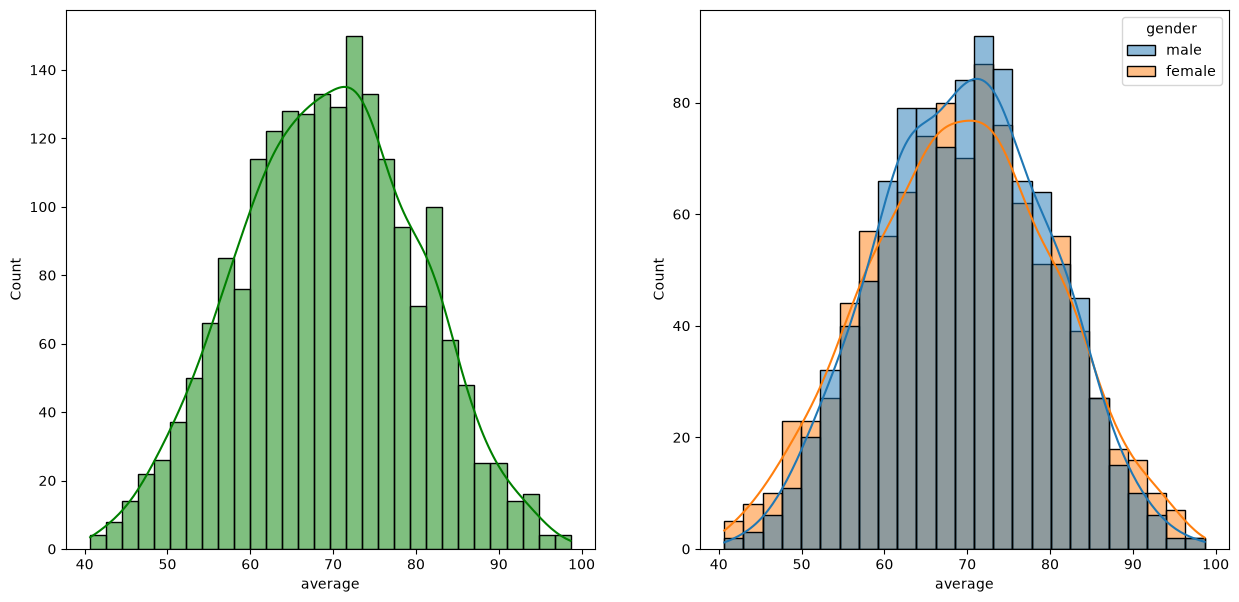

In [26]:
fig, axs = plt.subplots(1, 2, figsize=(15, 7))
plt.subplot(121)
sns.histplot(data=df, x='average', bins=30, kde=True, color='g')
plt.subplot(122)
sns.histplot(data=df, x='average', kde=True, hue='gender')
plt.show()

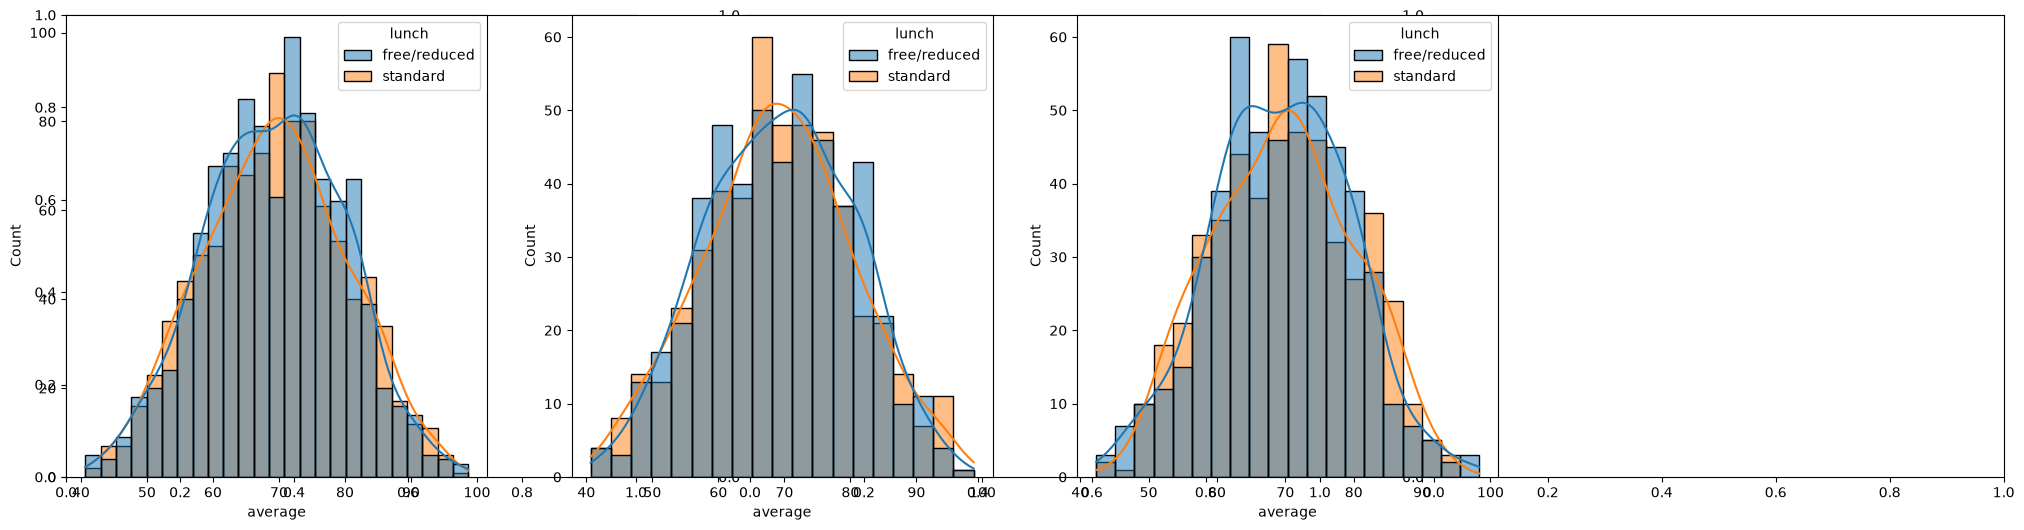

In [27]:
plt.subplots(1, 3, figsize=(25, 6))
plt.subplot(141)
sns.histplot(data=df, x='average', kde=True, hue='lunch')
plt.subplot(142)
sns.histplot(data=df[df.gender == 'female'], x='average', kde=True, hue='lunch')
plt.subplot(143)
sns.histplot(data=df[df.gender == 'male'], x='average', kde=True, hue='lunch')
plt.show()